In [37]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset("titanic")
df.to_csv("../data/raw/titanic.csv", index=False)
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [38]:
print(df.shape)
df.info()


(891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [39]:
df.isnull().sum().sort_values(ascending=False) 

deck           688
age            177
embarked         2
embark_town      2
sex              0
pclass           0
survived         0
fare             0
parch            0
sibsp            0
class            0
adult_male       0
who              0
alive            0
alone            0
dtype: int64

In [40]:
print("Overall survival rate:", round(df["survived"].mean() * 100, 1), "%")

df.groupby("sex")["survived"].mean().mul(100).round(1)


Overall survival rate: 38.4 %


sex
female    74.2
male      18.9
Name: survived, dtype: float64

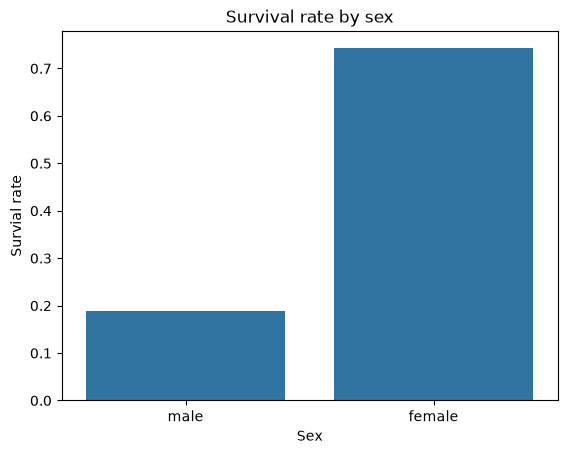

In [41]:
import matplotlib.pyplot as plt

sns.barplot(data=df, x="sex", y="survived", errorbar=None)
plt.title("Survival rate by sex")
plt.ylabel("Survial rate")
plt.xlabel("Sex")
plt.savefig("../reports/figures/survival_by_sex.png", dpi=150, bbox_inches="tight")
plt.show()


pclass
1    63.0
2    47.3
3    24.2
Name: survived, dtype: float64


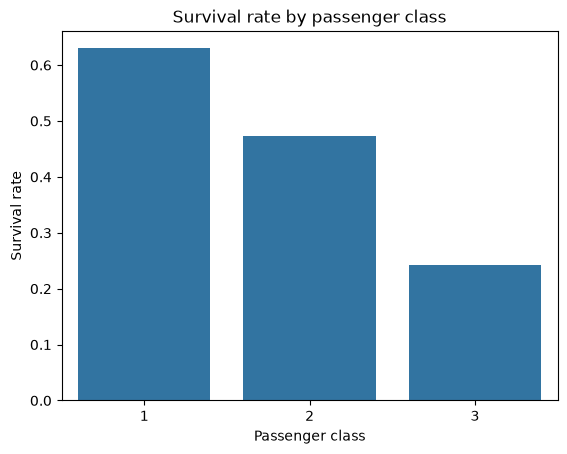

In [42]:
print(df.groupby("pclass")["survived"].mean().mul(100).round(1))

sns.barplot(data=df, x="pclass", y="survived", errorbar=None)
plt.title("Survival rate by passenger class")
plt.ylabel("Survival rate")
plt.xlabel("Passenger class")
plt.savefig("../reports/figures/survival_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

pclass  sex   
1       female    96.8
        male      36.9
2       female    92.1
        male      15.7
3       female    50.0
        male      13.5
Name: survived, dtype: float64


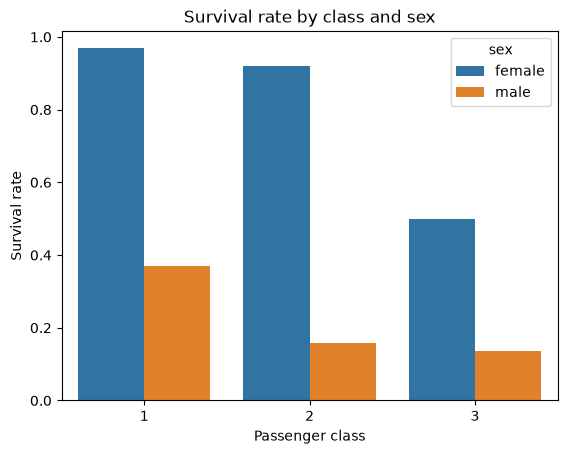

In [43]:
print(df.groupby(["pclass", "sex"])["survived"].mean().mul(100).round(1))

sns.barplot(data=df, x="pclass", y="survived", hue="sex", errorbar=None)
plt.title("Survival rate by class and sex")
plt.ylabel("Survival rate")
plt.xlabel("Passenger class")
plt.savefig("../reports/figures/survival_by_class_and_sex.png", dpi=150, bbox_inches="tight")
plt.show()


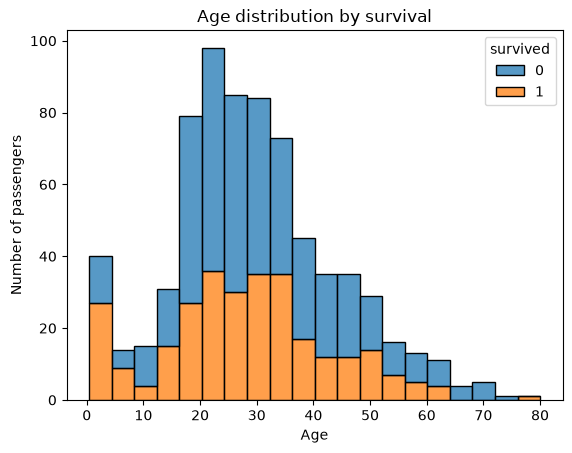

In [44]:
sns.histplot(data=df, x="age", hue="survived", bins=20, multiple="stack")
plt.title("Age distribution by survival")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.savefig("../reports/figures/age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


age_group
Child          58.0
Teen           42.9
Young adult    38.3
Adult          40.0
Senior         22.7
Name: survived, dtype: float64


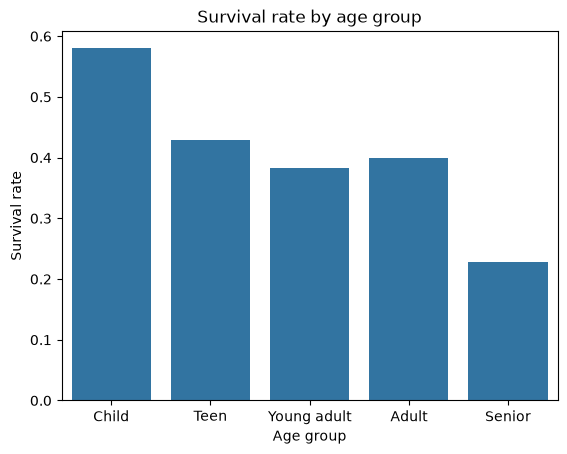

In [45]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young adult", "Adult", "Senior"]
)

print(df.groupby("age_group", observed=True)["survived"].mean().mul(100).round(1))

sns.barplot(data=df, x="age_group", y="survived", errorbar=None)
plt.title("Survival rate by age group")
plt.ylabel("Survival rate")
plt.xlabel("Age group")
plt.savefig("../reports/figures/survival_by_age_group.png", dpi=150, bbox_inches="tight")
plt.show()